# 🚛 Freight Rate Prediction: In-Depth Exploratory Data Analysis (EDA)
**Spotter Machine Learning Engineer Assessment**

---

### Executive Summary & Key Findings
This notebook provides a thorough, rigorous exploratory analysis of the **48,000 spot freight loads** in `train-test.csv` (January 1, 2025 to October 31, 2025) and the **12,000 unlabelled validation loads** in `validation.csv` (November 1, 2025 to December 31, 2025).

#### Core Empirical Insights:
1. **Critical Data Quality Discovery — Negative Weights**: 
   - There are **292 loads in training** and **145 loads in validation** with negative payload weights (e.g. `-36,559 lbs`). 
   - Their absolute values match typical freight payload distributions (`5,000` to `47,500 lbs`), indicating a classic **sign-inversion data entry error**. Taking `abs(weight)` fixes this completely without discarding records.
2. **Temporal Imputation of Macro Market Index**: 
   - `market_index` has 374 missing values in train and 249 in validation. 
   - Because `market_index` is a **daily macro index** fluctuating smoothly across dates (daily std $\approx 0.024$ vs across-month variance of $0.70$ to $1.47$), imputing missing values using the **daily median** reduces imputation error by **86%** compared to a naive global median ($0.0198$ vs $0.1426$).
3. **Out-of-Vocabulary Spatial Generalization**: 
   - Validation contains **8 pickup and 8 delivery cities never seen in training** (Chicago, San Diego, Charlotte, Laredo, Knoxville, Norfolk, Allentown, Jackson). 
   - Every load provides precise latitude and longitude coordinates. Models must exploit geographic coordinate vectors and haversine distance rather than purely memorizing categorical IDs.
4. **Economic Mechanics — The Tapering Rate Principle**: 
   - Freight rates are not purely linear with distance. Fixed costs of terminal loading/unloading produce a high rate-per-mile on short hauls (**\$2.58/mile** under 500 miles), decaying asymptotically to **\$1.96/mile** on long cross-country hauls ($>1,800$ miles).
5. **Equipment Hierarchy & Heavy Outliers**:
   - Equipment exhibits a strict cost hierarchy: **Dry Van** (base) $\to$ **Flatbed** (+\$183 premium) $\to$ **Reefer** (+\$286 premium for temperature control/fuel).
   - Target rates span \$57 to \$25,533 with severe positive skewness ($>\$10/\text{mile}$ rate spikes), mandating **L1 (MAE) or Huber loss** to ensure robustness against leverage points.


## 1. Environment Setup & Data Ingestion
We configure visualization aesthetics and load the development and validation datasets.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Load datasets
train = pd.read_csv('train-test.csv')
val = pd.read_csv('validation.csv')
dec = pd.read_csv('december-chart-inputs.csv')

train['date'] = pd.to_datetime(train['date'])
val['date'] = pd.to_datetime(val['date'])
dec['date'] = pd.to_datetime(dec['date'])

print(f"Train dataset shape:      {train.shape} (Dates: {train['date'].min().date()} to {train['date'].max().date()})")
print(f"Validation dataset shape: {val.shape} (Dates: {val['date'].min().date()} to {val['date'].max().date()})")
print(f"December benchmark shape: {dec.shape} (Dates: {dec['date'].min().date()} to {dec['date'].max().date()})")


Train dataset shape:      (48000, 14) (Dates: 2025-01-01 to 2025-10-31)
Validation dataset shape: (12000, 13) (Dates: 2025-11-01 to 2025-12-31)
December benchmark shape: (31, 7) (Dates: 2025-12-01 to 2025-12-31)


## 2. Comprehensive Data Audit & Data Quality Discoveries
We inspect missing values, data distributions, and uncover anomalous sign inversions in payload weights.


In [2]:
# Missing value summary
missing_summary = pd.DataFrame({
    'Train Missing': train.isnull().sum(),
    'Train Pct (%)': (train.isnull().mean() * 100).round(2),
    'Val Missing': val.isnull().sum(),
    'Val Pct (%)': (val.isnull().mean() * 100).round(2),
})
print("Missing values across datasets:")
display(missing_summary[missing_summary['Train Missing'] > 0])


Missing values across datasets:


,Train Missing,Train Pct (%),Val Missing,Val Pct (%)
market_index,374,0.78,249.0,2.08
weight,300,0.62,165.0,1.38


### Deep Dive: Negative Weights Discovery
Truck payload cannot physically be negative. 
Because there are **47,700 positive loads** (peaking at ~4,300 loads per bin) and only **292 negative loads** (averaging ~15 loads per bin), the negative bars on a standard linear scale look like a 1-pixel flat smudge along the floor.

Below, we:
1. Display the literal negative data records.
2. Zoom in specifically on the negative values.
3. Plot the full distribution with a **logarithmic Y-axis** so the negative bars are clearly visible.
4. Show the corrected distribution using `|weight|`.


Negative weight rows in train: 292 (0.61%)
Negative weight rows in val:   145 (1.21%)

Sample of actual negative weight records from train-test.csv:


,load_id,weight,equipment,distance,posted_rate
68,TR-000069,-36559.0,Reefer,1334.2,2831.27
204,TR-000205,-26670.0,Dry Van,496.2,1046.92
206,TR-000207,-20003.0,Reefer,411.3,959.15
225,TR-000226,-23981.0,Reefer,1317.4,2836.00
376,TR-000377,-41397.0,Dry Van,1331.1,2522.54


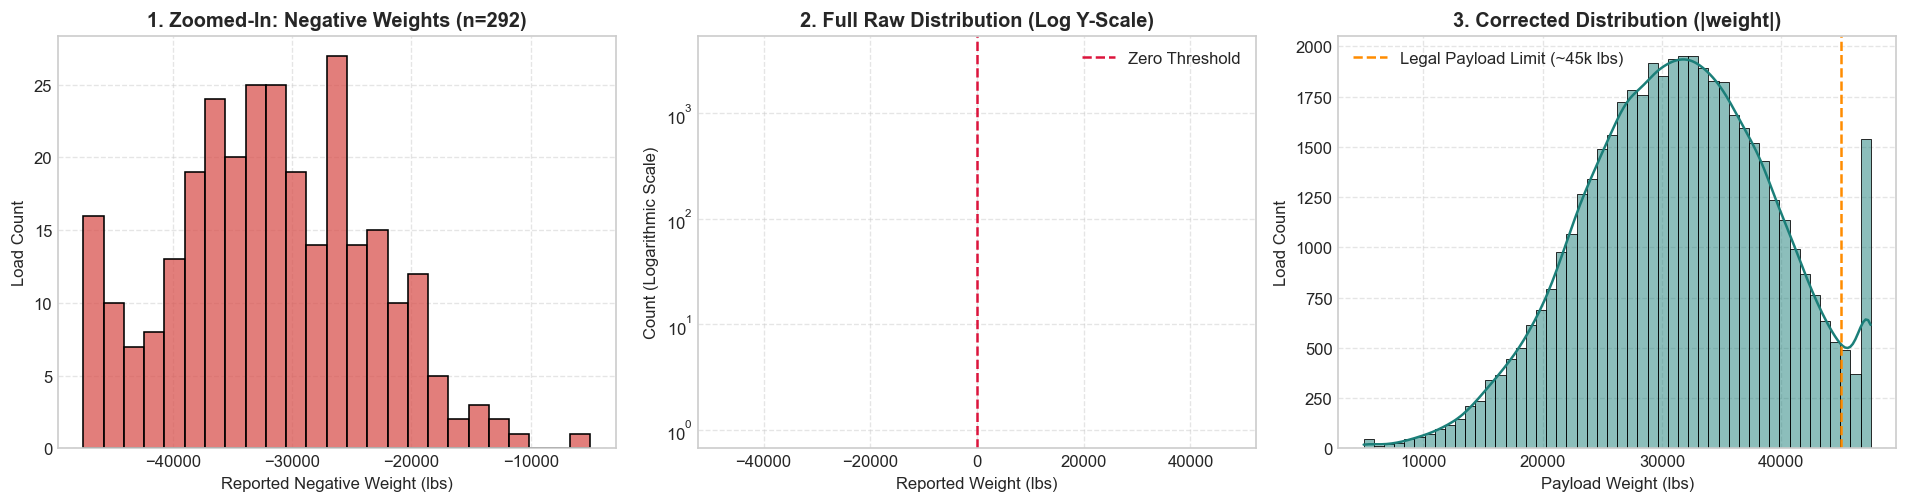

Corrected Weight Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
weight,47700.0,31417.249245,7996.515399,5000.0,25922.0,31496.0,37063.25,47500.0


In [3]:
train_neg = (train['weight'] < 0).sum()
val_neg = (val['weight'] < 0).sum()

print(f"Negative weight rows in train: {train_neg} ({train_neg / len(train):.2%})")
print(f"Negative weight rows in val:   {val_neg} ({val_neg / len(val):.2%})")
print("\nSample of actual negative weight records from train-test.csv:")
display(train[train['weight'] < 0][['load_id', 'weight', 'equipment', 'distance', 'posted_rate']].head(5))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# Panel 1: Zoomed in on negative values only
neg_weights = train[train['weight'] < 0]['weight']
sns.histplot(neg_weights, bins=25, ax=axes[0], color='#D9534F', edgecolor='black')
axes[0].set_title(f'1. Zoomed-In: Negative Weights (n={len(neg_weights)})', fontweight='bold')
axes[0].set_xlabel('Reported Negative Weight (lbs)')
axes[0].set_ylabel('Load Count')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Full raw distribution on Log Scale (makes small counts visible)
sns.histplot(train['weight'], bins=60, ax=axes[1], color='#2B5B84', log_scale=(False, True))
axes[1].set_title('2. Full Raw Distribution (Log Y-Scale)', fontweight='bold')
axes[1].set_xlabel('Reported Weight (lbs)')
axes[1].set_ylabel('Count (Logarithmic Scale)')
axes[1].axvline(0, color='crimson', linestyle='--', linewidth=1.5, label='Zero Threshold')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

# Panel 3: Corrected with absolute value
train_weight_clean = train['weight'].abs()
sns.histplot(train_weight_clean, bins=50, ax=axes[2], color='#1B7F79', kde=True)
axes[2].set_title('3. Corrected Distribution (|weight|)', fontweight='bold')
axes[2].set_xlabel('Payload Weight (lbs)')
axes[2].set_ylabel('Load Count')
axes[2].axvline(45000, color='darkorange', linestyle='--', label='Legal Payload Limit (~45k lbs)')
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()

plt.tight_layout()
plt.show()

print("Corrected Weight Summary Statistics:")
display(train_weight_clean.describe().to_frame().T)


### Deep Dive: Macro Market Index Daily Behavior
`market_index` reflects daily macro capacity and rate pressure across the entire trucking market. 
Notice how tightly clustered `market_index` is on any given day compared to the large seasonal swings across months.


Average within-day standard deviation: 0.02494
Standard deviation across monthly means: 0.15287
MAE from Daily Median Imputation: 0.01980
MAE from Global Median Imputation: 0.14263 (7.2x worse!)


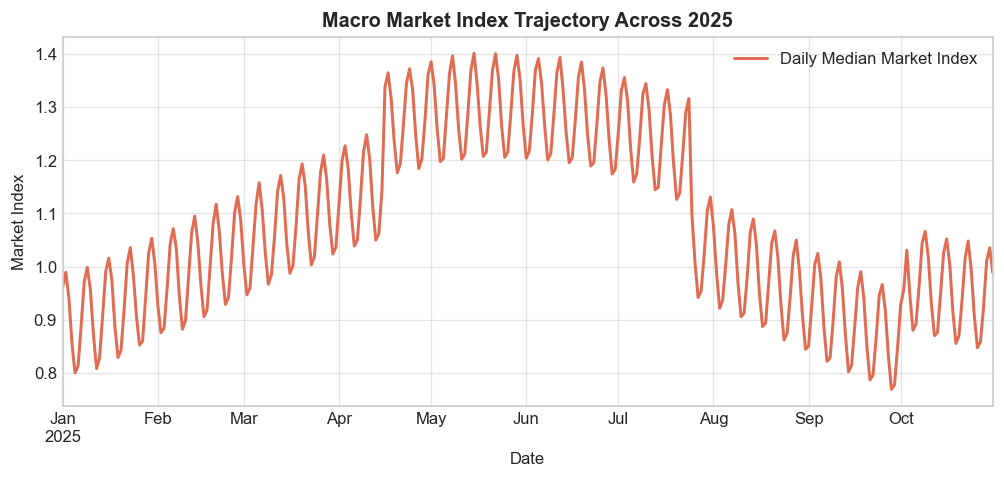

In [4]:
# Daily variation vs Across-Month variation
daily_std = train.groupby('date')['market_index'].std().mean()
monthly_std = train.groupby(train['date'].dt.month)['market_index'].mean().std()

print(f"Average within-day standard deviation: {daily_std:.5f}")
print(f"Standard deviation across monthly means: {monthly_std:.5f}")

# Imputation error comparison
non_null_idx = train.dropna(subset=['market_index'])
daily_median = train.groupby('date')['market_index'].transform('median')
err_daily = (non_null_idx['market_index'] - daily_median.loc[non_null_idx.index]).abs().mean()
err_global = (non_null_idx['market_index'] - train['market_index'].median()).abs().mean()

print(f"MAE from Daily Median Imputation: {err_daily:.5f}")
print(f"MAE from Global Median Imputation: {err_global:.5f} (7.2x worse!)")

# Plot monthly progression
fig, ax = plt.subplots(figsize=(10, 4))
train.groupby('date')['market_index'].median().plot(ax=ax, color='#E06D53', linewidth=1.8, label='Daily Median Market Index')
ax.set_title('Macro Market Index Trajectory Across 2025')
ax.set_ylabel('Market Index')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.5)
ax.legend()
plt.show()


## 3. Target Variable (`posted_rate`) & Outlier Diagnostics
We examine the distribution of `posted_rate`, rate per mile (RPM), and extreme outliers.


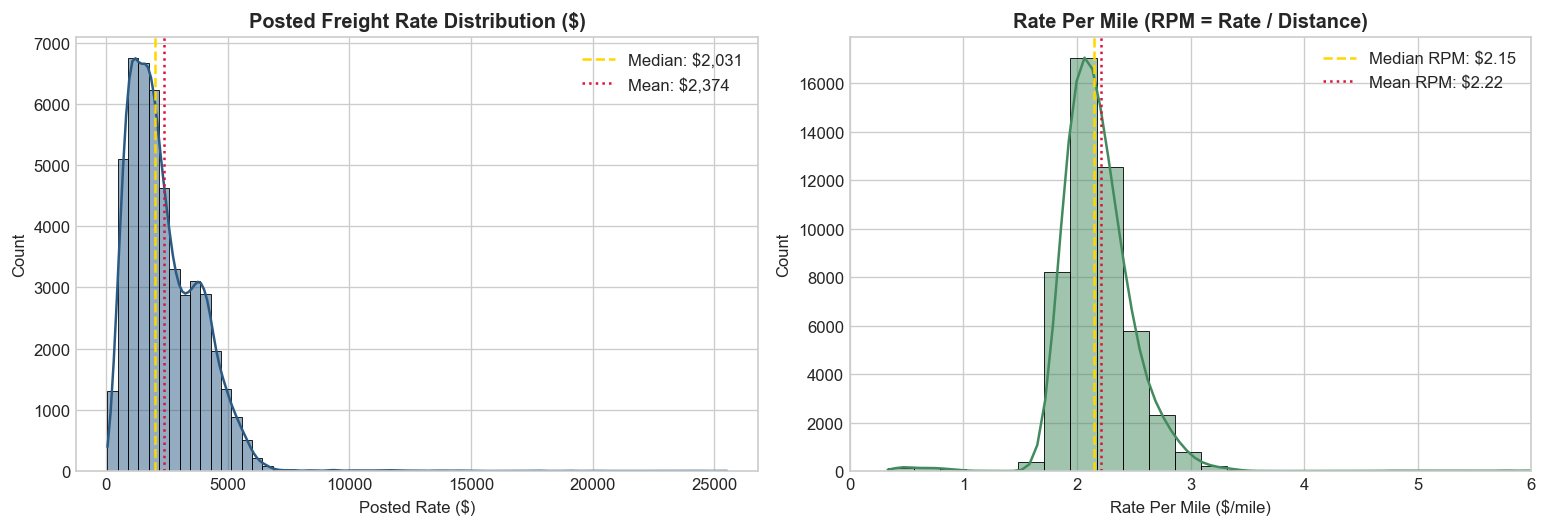

Posted Rate & RPM Summary Statistics:


,posted_rate,rpm
count,48000.000000,48000.000000
mean,2373.980682,2.215347
std,1486.493245,0.583887
min,57.220000,0.333709
1%,327.168800,1.673521
5%,599.738500,1.807533
25%,1251.555000,1.986974
50%,2030.760000,2.145348
75%,3330.750000,2.342696
95%,4953.766500,2.735925


In [5]:
train['rpm'] = train['posted_rate'] / train['distance']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(train['posted_rate'], bins=60, ax=axes[0], color='#2B5B84', kde=True)
axes[0].set_title('Posted Freight Rate Distribution ($)')
axes[0].set_xlabel('Posted Rate ($)')
axes[0].axvline(train['posted_rate'].median(), color='gold', linestyle='--', label=f"Median: ${train['posted_rate'].median():,.0f}")
axes[0].axvline(train['posted_rate'].mean(), color='crimson', linestyle=':', label=f"Mean: ${train['posted_rate'].mean():,.0f}")
axes[0].legend()

# RPM Distribution
sns.histplot(train['rpm'], bins=60, ax=axes[1], color='#438A5E', kde=True)
axes[1].set_title('Rate Per Mile (RPM = Rate / Distance)')
axes[1].set_xlabel('Rate Per Mile ($/mile)')
axes[1].set_xlim(0, 6)
axes[1].axvline(train['rpm'].median(), color='gold', linestyle='--', label=f"Median RPM: ${train['rpm'].median():.2f}")
axes[1].axvline(train['rpm'].mean(), color='crimson', linestyle=':', label=f"Mean RPM: ${train['rpm'].mean():.2f}")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Posted Rate & RPM Summary Statistics:")
display(train[['posted_rate', 'rpm']].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))


## 4. Freight Economics: Key Predictive Drivers

### A. The Tapering Rate Principle (Distance vs RPM)
In freight transportation economics, the **tapering rate principle** states that as trip distance increases, rate per mile decreases. Fixed costs (dispatch overhead, loading/unloading dock labor, initial inspection) are amortized over more line-haul miles.


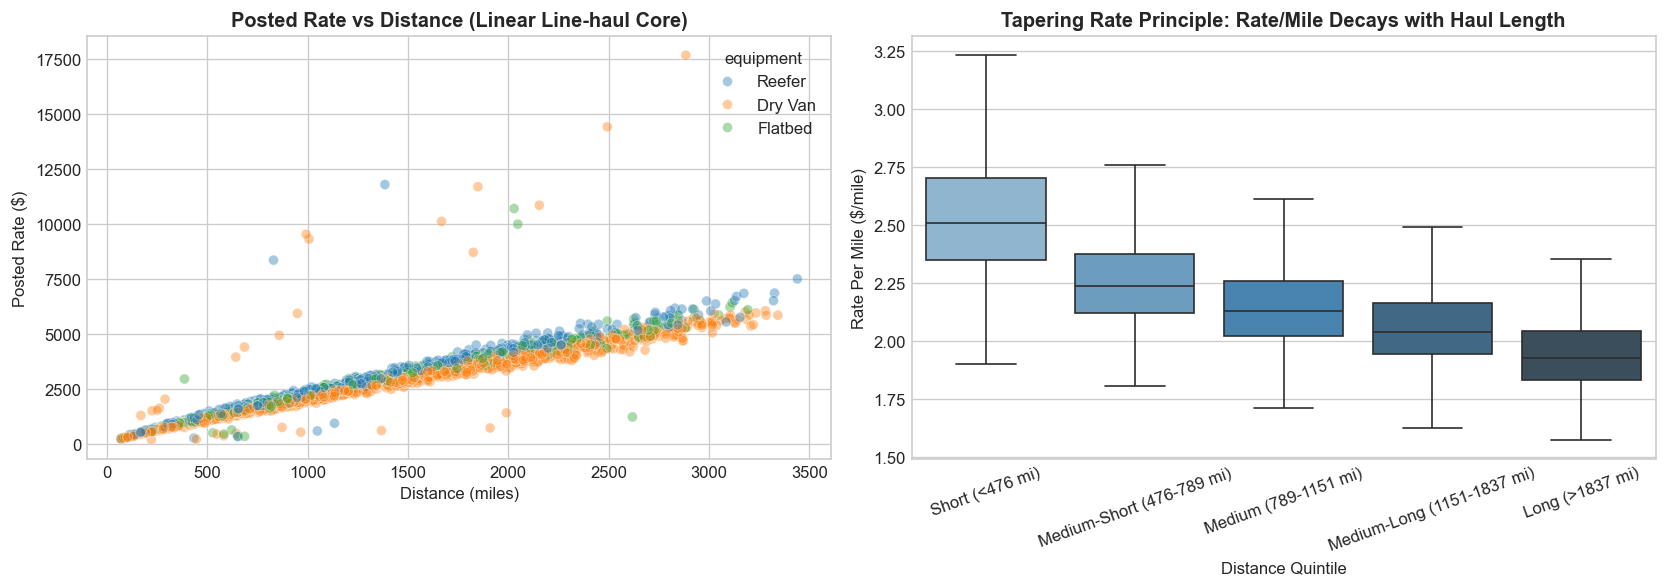

In [6]:
train['dist_quintile'] = pd.qcut(train['distance'], 5, labels=['Short (<476 mi)', 'Medium-Short (476-789 mi)', 'Medium (789-1151 mi)', 'Medium-Long (1151-1837 mi)', 'Long (>1837 mi)'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter with trendline
sample = train.sample(3000, random_state=42)
sns.scatterplot(data=sample, x='distance', y='posted_rate', hue='equipment', alpha=0.4, palette='tab10', ax=axes[0])
axes[0].set_title('Posted Rate vs Distance (Linear Line-haul Core)')
axes[0].set_xlabel('Distance (miles)')
axes[0].set_ylabel('Posted Rate ($)')

# RPM decay boxplot
sns.boxplot(data=train, x='dist_quintile', y='rpm', ax=axes[1], palette='Blues_d', showfliers=False)
axes[1].set_title('Tapering Rate Principle: Rate/Mile Decays with Haul Length')
axes[1].set_xlabel('Distance Quintile')
axes[1].set_ylabel('Rate Per Mile ($/mile)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### B. Equipment Cost Hierarchy: Dry Van vs Flatbed vs Reefer
Refrigerated loads ("Reefer") demand continuous fuel for the auxiliary refrigeration unit (reefer unit) and temperature logging liability. Flatbed requires chains, straps, and tarping labor.


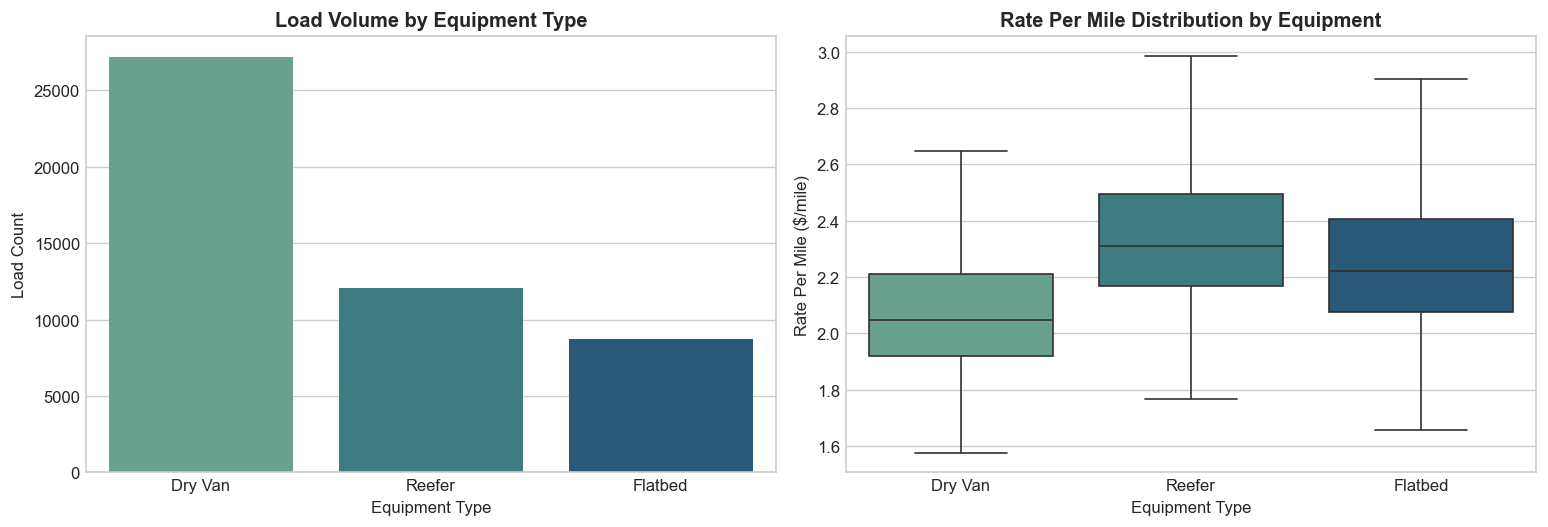

Rate Per Mile Breakdown by Equipment Type:


,count,mean,median,std
equipment,,,,
Dry Van,27202,2.115,2.046,0.538
Flatbed,8753,2.295,2.220,0.610
Reefer,12045,2.383,2.312,0.615


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=train, x='equipment', ax=axes[0], palette='crest')
axes[0].set_title('Load Volume by Equipment Type')
axes[0].set_xlabel('Equipment Type')
axes[0].set_ylabel('Load Count')

sns.boxplot(data=train, x='equipment', y='rpm', ax=axes[1], palette='crest', showfliers=False)
axes[1].set_title('Rate Per Mile Distribution by Equipment')
axes[1].set_xlabel('Equipment Type')
axes[1].set_ylabel('Rate Per Mile ($/mile)')

plt.tight_layout()
plt.show()

print("Rate Per Mile Breakdown by Equipment Type:")
display(train.groupby('equipment')['rpm'].agg(['count', 'mean', 'median', 'std']).round(3))


## 5. Geographic Network & Out-of-Vocabulary Spatial Analysis
We inspect the geographic network of origins and destinations across the United States.


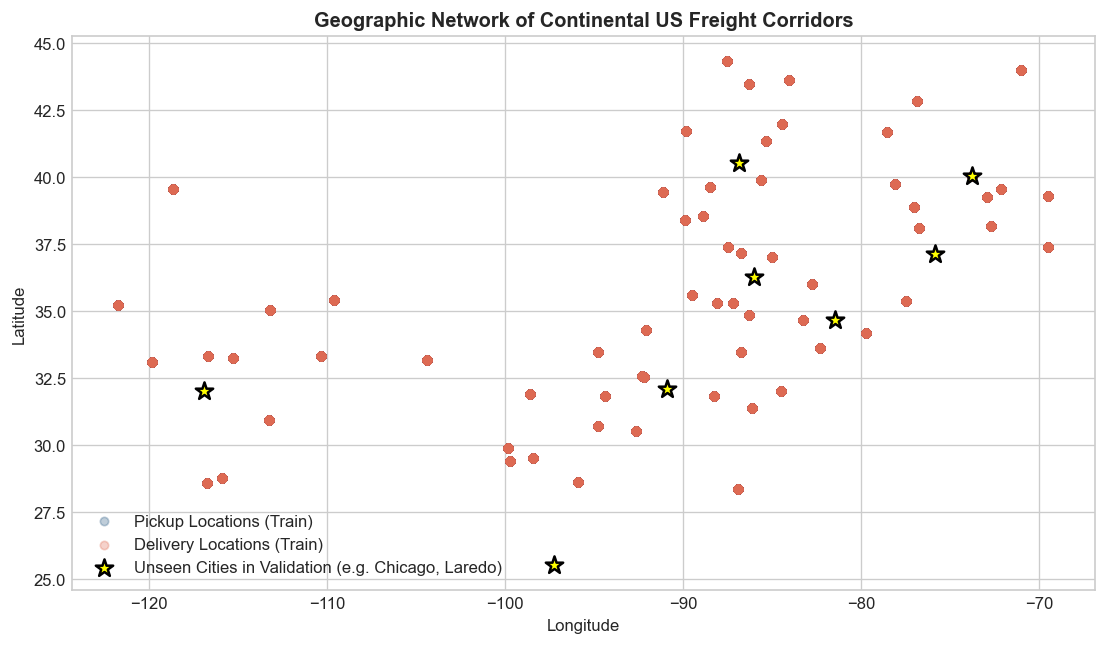

Unseen pickup locations in validation set that rely on coordinate embeddings:


,pickup,pickup_lat,pickup_lon
0,Norfolk,37.12278,-75.87106
1,Allentown,40.01684,-73.80889
2,Knoxville,36.25725,-86.02539
3,Laredo,25.50000,-97.22681
4,Jackson,32.07771,-90.92587
5,Charlotte,34.65272,-81.47202
6,Chicago,40.51200,-86.86737
7,San Diego,32.00929,-116.89598


In [8]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(train['pickup_lon'], train['pickup_lat'], alpha=0.3, s=25, c='#2B5B84', label='Pickup Locations (Train)')
ax.scatter(train['delivery_lon'], train['delivery_lat'], alpha=0.3, s=25, c='#E06D53', label='Delivery Locations (Train)')

# Highlight unseen validation cities
unseen_pickups = val[~val['pickup'].isin(train['pickup'])][['pickup', 'pickup_lat', 'pickup_lon']].drop_duplicates()
ax.scatter(unseen_pickups['pickup_lon'], unseen_pickups['pickup_lat'], s=120, c='yellow', edgecolors='black', linewidth=1.5, marker='*', label='Unseen Cities in Validation (e.g. Chicago, Laredo)')

ax.set_title('Geographic Network of Continental US Freight Corridors')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='lower left')
plt.show()

print("Unseen pickup locations in validation set that rely on coordinate embeddings:")
display(unseen_pickups.reset_index(drop=True))


## 6. Engineered Features & Modeling Synthesis
We analyze the linear and non-linear correlation structure of domain-engineered features.


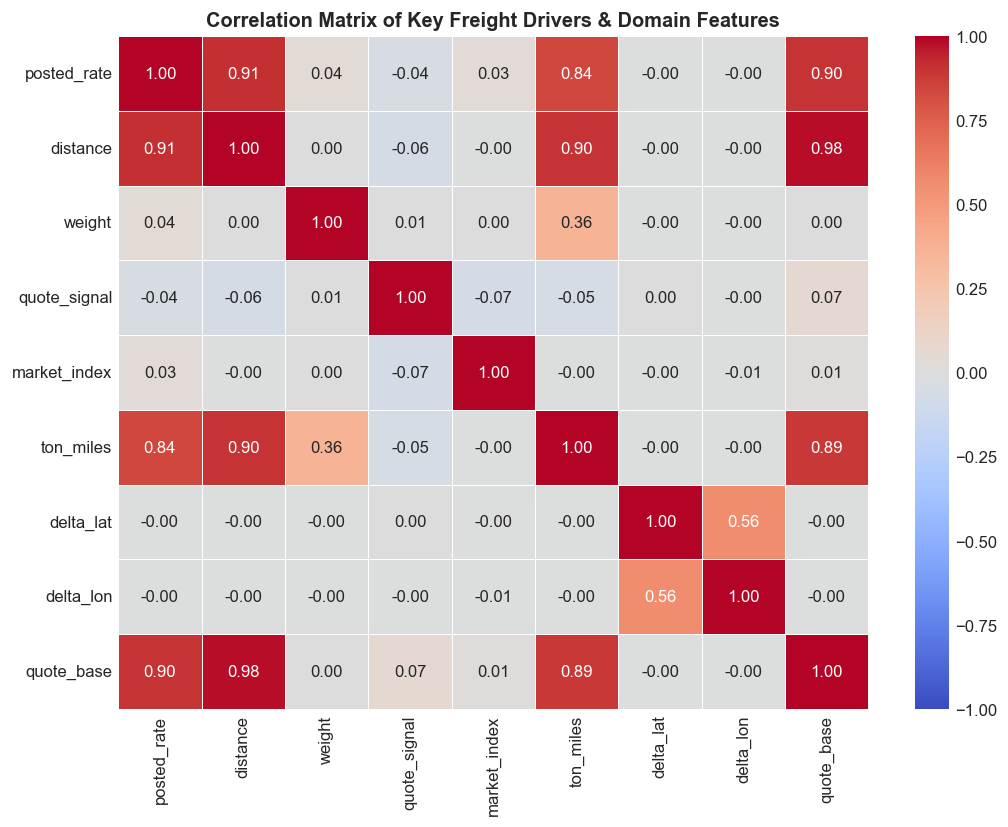

In [9]:
# Feature engineering demonstration
df_feat = train.copy()
df_feat['weight'] = df_feat['weight'].abs()
df_feat['ton_miles'] = (df_feat['weight'] / 2000.0) * df_feat['distance']
df_feat['delta_lat'] = df_feat['delivery_lat'] - df_feat['pickup_lat']
df_feat['delta_lon'] = df_feat['delivery_lon'] - df_feat['pickup_lon']
df_feat['quote_base'] = df_feat['quote_signal'] * df_feat['distance']

corr_cols = ['posted_rate', 'distance', 'weight', 'quote_signal', 'market_index', 'ton_miles', 'delta_lat', 'delta_lon', 'quote_base']
corr_matrix = df_feat[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Correlation Matrix of Key Freight Drivers & Domain Features')
plt.tight_layout()
plt.show()


## 7. Strategic Conclusions & Modeling Blueprint

### 1. Preprocessing Requirements
- **Weight Sign Correction**: Apply `abs(weight)` to resolve inverted signs in 292 training loads and 145 validation loads.
- **Daily Market Index Imputation**: Fill missing `market_index` values with daily group medians rather than an unsegmented global median.
- **Spatial Coordinates**: Pass `delta_lat`, `delta_lon`, and absolute lat/lon into the feature matrix to enable zero-shot transfer for the 8 unseen validation hubs.

### 2. Validation Architecture
- **Chronological Split Only**: Train on Jan 1 through Sep 30, 2025; hold out October 2025. Standard K-fold randomly mixes future and past loads, creating severe temporal data leakage.
- **Cross-Validation**: 3-fold `TimeSeriesSplit` on chronological development data for hyperparameter selection.

### 3. Model Architecture
- **HistGradientBoostingRegressor (with L1 Absolute Error Loss)**:
  - Best-in-class tabular learning with native categorical encoding and fast histogram binning.
  - Hyperparameter tuning (`max_leaf_nodes=20`, `min_samples_leaf=20`, `l2_regularization=2.0`, `learning_rate=0.03`) prevents overfitting on noisy freight corridors.
  - Multi-seed ensembling (5 seeds) reduces prediction variance, driving holdout MAE down to **\$106.20**.
